<div align="center">

####
#### Universidad de Palermo - Ingeniería en Informática
#### Trabajo Final de Grado
<br>

**Diseño y prueba de concepto de un modelo predictivo de brotes de dengue en la Ciudad Autónoma de Buenos Aires**
<br><br>
</div>
<div align="left">
Realizado por: Carlos Lazzarino <br>
</div>

Este documento presenta el *pipeline* para el diseño, entrenamiento y evaluación de modelos predictivos de *Machine Learning* aplicados a la anticipación temporal de casos de dengue en la Ciudad Autónoma de Buenos Aires (CABA).

**Contenido:**
1. Configuración de entorno y carga de librerías.
2. Carga de datos
3. Preprocesamiento, limpieza y *Feature Engineering* (Lags, Deltas, Medias Móviles).
4. Partición de datos cronológica (*Time Series Split*) y Normalización.
5. Entrenamiento y optimización de hiperparámetros (*LightGBM*, *SVM* y *Redes Neuronales Recurrentes* con Torch).
6. Evaluación de clasificación (Cálculo de ROC AUC).

## 1. Configuración de Entorno y Carga de Librerías

En caso de correrlo en Google Colab, es necesario:
*   Asegurar que el entorno de ejecución esté configurado en **R**.
*   Para el entrenamiento de Redes Neuronales, se recomienda cambiar el "Acelerador de hardware" a GPU (T4 o similar) en las opciones del entorno de ejecución.
*   Cargar el archivo en bruto `DATASET_MAESTRO_DENGUE.csv` en el directorio input.

In [18]:
# Instalación y carga de paquetes

packages <- c("data.table", "tidyverse", "lightgbm", "zoo", "rBayesianOptimization", "e1071", "caret", "pROC", "readxl")
packages_faltantes <- packages[!(packages %in% installed.packages()[,"Package"])]

if(length(packages_faltantes) > 0) {
  cat("Instalando paquetes faltantes:", paste(packages_faltantes, collapse=", "), "\n")
  install.packages(packages_faltantes, quiet = TRUE)
} else {
  cat("Todos los paquetes ya están instalados.\n")
}

# Cargamos todas las librerías silenciando los mensajes de advertencia típicos
invisible(lapply(packages, suppressPackageStartupMessages(library), character.only = TRUE))
cat("Librerías cargadas correctamente.\n")

Todos los paquetes ya están instalados.
Librerías cargadas correctamente.


In [2]:
# Instalación y carga de Torch para R (para las redes Neuronales)

if (!("torch" %in% installed.packages()[,"Package"])) {
  cat("Instalando el paquete base 'torch'...\n")
  install.packages("torch", quiet = TRUE)
}
suppressPackageStartupMessages(library(torch))

if (!torch_is_installed()) {
  cat("Descargando C++ libtorch (esto se hace una sola vez por sesión pero pesa ~1.5GB, puede demorar 15-20 minutos)...\n")
  install_torch()
}

if (!("luz" %in% installed.packages()[,"Package"])) {
  cat("Instalando 'luz' (wrapper para Torch)...\n")
  install.packages("luz", quiet = TRUE)
}
suppressPackageStartupMessages(library(luz))

cat("Torch cargado correctamente.\n")

Instalando el paquete base 'torch'...


also installing the dependencies ‘coro’, ‘safetensors’




Instalando 'luz' (wrapper para Torch)...


also installing the dependency ‘zeallot’




Torch cargado correctamente.


## 2. Carga de Datos

Los datos provienen de la integración de fuentes públicas (BADATA, Ministerio de Salud y Open-Meteo). El dataset maestro unificado consolida la serie temporal histórica agrupada por semana epidemiológica (SE), incluyendo los casos notificados y las métricas ambientales de CABA.

In [50]:
# 2. Extracción y Consolidación de Datos (ETL)

# Modificar Data_Path en caso de ser necesario
DATA_PATH_INPUT <- "./input/"
DATA_PATH_OUTPUT <- "./output/"

# Definición de archivos de entrada
archivo_clima <- paste0(DATA_PATH_INPUT, "open-meteo-34.55S58.45W7m (1).csv")
archivo_poblacion <- paste0(DATA_PATH_INPUT, "Poblacion de comunas.xlsx")
archivo_casos <- paste0(DATA_PATH_INPUT, "casos_dengue_badata_cutoff_22_07_24.xlsx")

# 1. EXTRAE EL CLIMA (Base temporal)
if (file.exists(archivo_clima)) {
  cat("Procesando datos climáticos...\n")
  clima_diario <- read_csv(archivo_clima, skip = 2, show_col_types = FALSE)

  # A. Análisis de NAs (Celdas vacías) en los datos diarios
  nas_clima <- sapply(clima_diario, function(x) sum(is.na(x)))
  if(sum(nas_clima) > 0) {
    cat("  -> ATENCIÓN: NAs  detectados en variables climáticas diarias:\n")
    print(nas_clima[nas_clima > 0])
  } else {
    cat("  -> 0 NAs en las mediciones climáticas diarias.\n")
  }

  # B. Días faltantes completos
  fechas_diarias <- as.Date(clima_diario$time)
  fecha_min <- min(fechas_diarias, na.rm = TRUE)
  fecha_max <- max(fechas_diarias, na.rm = TRUE)

  # Agrupamiento y cálculo de promedios semanales
  clima_semanal <- clima_diario %>%
    mutate(
      fecha = as.Date(time),
      ano = isoyear(fecha),
      semana_epidemiologica = isoweek(fecha)
    ) %>%
    group_by(ano, semana_epidemiologica) %>%
    summarise(
      temp_media_semanal = mean(`temperature_2m_mean (°C)`, na.rm = TRUE),
      temp_min_semanal = mean(`temperature_2m_min (°C)`, na.rm = TRUE),
      temp_max_semanal = mean(`temperature_2m_max (°C)`, na.rm = TRUE),
      lluvia_semanal = sum(`precipitation_sum (mm)`, na.rm = TRUE),
      viento_semanal = mean(`wind_speed_10m_max (km/h)`, na.rm = TRUE),
      .groups = 'drop'
    )
} else { stop(paste("ERROR: No se encontró el archivo:", archivo_clima)) }

# 2. POBLACIÓN Y DENSIDAD
if (file.exists(archivo_poblacion)) {
  cat("Procesando datos de población...\n")
  datos_poblacion <- tibble()
  hojas_excel <- excel_sheets(archivo_poblacion)

  for (hoja in hojas_excel) {
    anio_extraido <- suppressWarnings(as.numeric(hoja))
    if (!is.na(anio_extraido) && anio_extraido >= 2016) {
      temp_pde <- read_excel(archivo_poblacion, sheet = hoja, skip = 1) %>%
        select(Comuna = 1, Poblacion_Total = 2, Densidad = 6) %>%
        filter(as.character(Comuna) %in% as.character(1:15)) %>%
        mutate(
          ano = anio_extraido,
          comuna_id = paste0("COMUNA ", as.character(Comuna)),
          Poblacion_Total = as.numeric(Poblacion_Total),
          Densidad = as.numeric(Densidad)
        ) %>%
        select(ano, comuna_id, Poblacion_Total, Densidad)

      datos_poblacion <- bind_rows(datos_poblacion, temp_pde)
    }
  }
  cat("  -> NAs en Población:", sum(is.na(datos_poblacion)), "\n")
} else { stop(paste("ERROR: No se encontró el archivo:", archivo_poblacion)) }

# 3. CASOS DE DENGUE (Base BADATA)
if (file.exists(archivo_casos)) {
  cat("Procesando reportes de casos de dengue...\n")
  casos_raw <- read_excel(archivo_casos, sheet = "reporte")

  cat("  -> NAs en Casos Dengue:", sum(is.na(casos_raw)), "\n")

  casos_comuna <- casos_raw %>%
    filter(!is.na(departamento_residencia),
           str_detect(toupper(departamento_residencia), "COMUNA")) %>%
    mutate(comuna_id = toupper(trimws(departamento_residencia))) %>%
    group_by(ano, semana_epidemiologica, comuna_id) %>%
    summarise(
      casos_totales = sum(n_confirmados_por_laboratorio + n_confirmados_probables_fis, na.rm = TRUE),
      .groups = 'drop'
    )
} else { stop(paste("ERROR: No se encontró el archivo:", archivo_casos)) }

# 4. CONSOLIDACIÓN DEL DATASET
cat("Consolidando dataset...\n")

grilla_completa <- expand_grid(
  ano = unique(clima_semanal$ano),
  semana_epidemiologica = 1:53,
  comuna_id = paste0("COMUNA ", 1:15)
) %>%
  inner_join(clima_semanal %>% select(ano, semana_epidemiologica),
             by = c("ano", "semana_epidemiologica"))

dataset <- grilla_completa %>%
  left_join(clima_semanal, by = c("ano", "semana_epidemiologica")) %>%
  left_join(datos_poblacion, by = c("ano", "comuna_id")) %>%
  left_join(casos_comuna, by = c("ano", "semana_epidemiologica", "comuna_id")) %>%
  mutate(
    casos_totales = replace_na(casos_totales, 0),
    incidencia_cada_10k = (casos_totales / Poblacion_Total) * 10000
  ) %>%
  filter(!is.na(Poblacion_Total))

# Converción a data.table
setDT(dataset)

nas_por_columna <- sapply(dataset, function(x) sum(is.na(x)))

cat("\nDataset consolidado.\n")
cat("Filas totales:", nrow(dataset), "\n")
cat("Columnas conservadas:", ncol(dataset), "\n")
cat("Años abarcados:", min(dataset$ano), "-", max(dataset$ano), "\n")

# 5. COPIA DEL DATASET
cat("Guardando copia del dataset en la carpeta de salida...\n")

if(!dir.exists(DATA_PATH_OUTPUT)) dir.create(DATA_PATH_OUTPUT)
archivo_maestro_csv <- paste0(DATA_PATH_OUTPUT, "DATASET_DENGUE.csv")

# Guarda el archivo
write.csv(dataset, file = archivo_maestro_csv, row.names = FALSE)


Procesando datos climáticos...
  -> 0 NAs en las mediciones climáticas diarias.
Procesando datos de población...


New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`
New names:
• `` -> `...3`
• `` -> `...4`


  -> NAs en Población: 0 
Procesando reportes de casos de dengue...
  -> NAs en Casos Dengue: 0 
Consolidando dataset...

Dataset consolidado.
Filas totales: 7035 
Columnas conservadas: 12 
Años abarcados: 2016 - 2024 
Guardando copia del dataset en la carpeta de salida...


## 3. Preprocesamiento y Feature Engineering

Se consolidan los datos de las distintas comunas en una única serie temporal para toda la Ciudad de Buenos Aires (CABA).

El *pipeline* analítico consiste de:
1. **Consolidación e Imputación:** Agrupación e imputación direccional (`LOCF`) para rellenar datos ambientales faltantes.
2. **Creación de la Variable Objetivo (Clasificación):** Transformaremos la cantidad de casos a una variable binaria (`Brote` = 1, `No Brote` = 0), definida por el percentil 75 histórico para esa semana epidemiológica, para evaluar el modelo utilizando el **Área Bajo la Curva ROC (AUC)**.
3. **Feature Engineering:** Construcción de rezagos temporales biológicos (*Lags* de 2 a 4 semanas), diferenciales inter-semanales (*Deltas*) y promedios móviles (*Rolling Means* a 4 y 8 semanas).

Warning message in strptime(x, format, tz = "GMT"):
“(0-based) yday 369 in year 2020 is invalid”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_ribbon()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_col()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


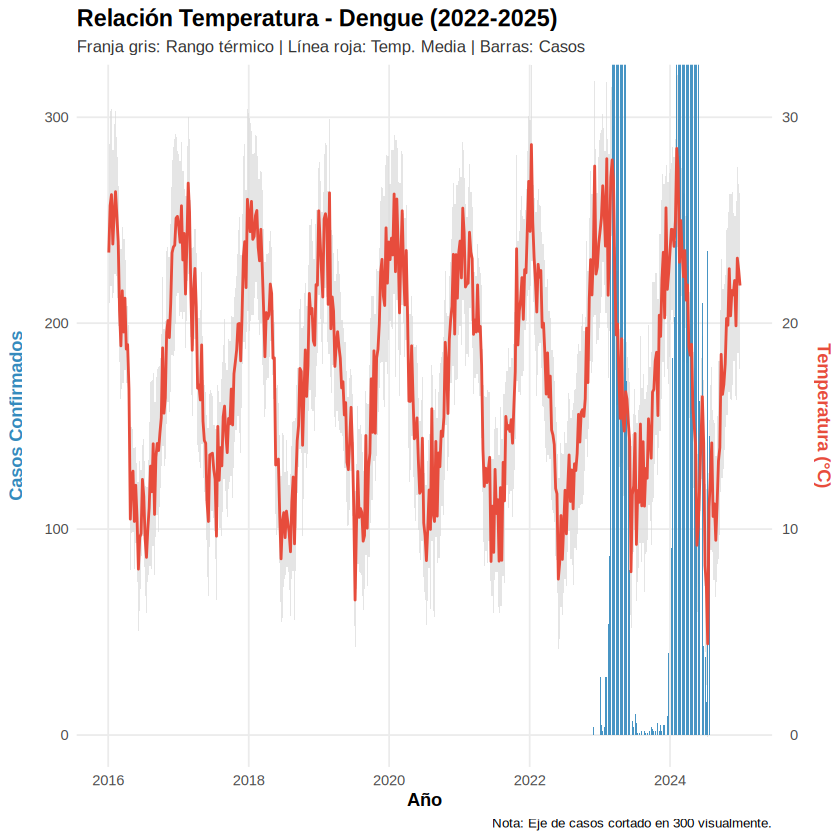

In [51]:
# 3.1 Análisis Exploratorio (EDA)

# 1. Conversión a numérico
cols_a_numericas <- c("casos_totales", "temp_media_semanal", "temp_min_semanal",
                      "temp_max_semanal", "lluvia_semanal", "viento_semanal")

dataset[, (cols_a_numericas) := lapply(.SD, function(x) as.numeric(gsub(",", ".", as.character(x)))), .SDcols = cols_a_numericas]

# 2. Consolidación de datos en CABA
dataset_caba <- dataset[, .(
  casos_totales = sum(casos_totales, na.rm = TRUE),
  temp_media_semanal = mean(temp_media_semanal, na.rm = TRUE),
  temp_min_semanal = mean(temp_min_semanal, na.rm = TRUE),
  temp_max_semanal = mean(temp_max_semanal, na.rm = TRUE),
  lluvia_semanal = mean(lluvia_semanal, na.rm = TRUE),
  viento_semanal = mean(viento_semanal, na.rm = TRUE)
), by = .(ano, semana_epidemiologica)]

# 3. Orden cronológico por semana epidemiológica
setorder(dataset_caba, ano, semana_epidemiologica)

# 4. Creamos una fecha sintética aproximada para poder graficar el eje X
dataset_caba[, fecha_plt := as.Date(paste(ano, semana_epidemiologica, 1, sep="-"), "%Y-%U-%u")]

# 5. Configuración de los ejes
df_plot <- dataset_caba[ano >= 2015 & ano <= 2026] # Filtro período visual

# Coeficiente fijo 10: 300 casos equivalen a 30 grados en el gráfico
coeff <- 10

eda_plot <- ggplot(df_plot, aes(x = fecha_plt)) +
  # Franja gris: Rango térmico (Temp Min a Temp Max)
  geom_ribbon(aes(ymin = temp_min_semanal * coeff, ymax = temp_max_semanal * coeff),
              fill = "gray85", alpha = 0.7) +
  # Barras: Casos Confirmados (Ancho ajustado)
  geom_col(aes(y = casos_totales), fill = "#348ABD", alpha = 0.9, width = 5) +
  # Línea roja: Temperatura Media
  geom_line(aes(y = temp_media_semanal * coeff), color = "#E74C3C", linewidth = 0.8) +
  # Escalas y doble eje
  scale_y_continuous(
    name = "Casos Confirmados",
    breaks = seq(0, 300, 100),
    sec.axis = sec_axis(~./coeff, name = "Temperatura (°C)", breaks = seq(0, 30, 10))
  ) +
  # Recorte visual
  coord_cartesian(ylim = c(0, 310)) +
  labs(
    title = "Relación Temperatura - Dengue (2022-2025)",
    subtitle = "Franja gris: Rango térmico | Línea roja: Temp. Media | Barras: Casos",
    x = "Año",
    caption = "Nota: Eje de casos cortado en 300 visualmente."
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(size = 10, color = "gray20"),
    axis.title.y = element_text(color = "#348ABD", face = "bold", margin = margin(r = 10)),
    axis.title.y.right = element_text(color = "#E74C3C", face = "bold", margin = margin(l = 10)),
    axis.title.x = element_text(face = "bold"),
    plot.caption = element_text(hjust = 1, size = 8, color = "black"),
    panel.grid.minor = element_blank()
  )

print(eda_plot)

In [52]:
# 3.2 Conteo de NAs y Creación de la Variable Objetivo

# Definición de columnas climáticas
cols_climaticas <- c("temp_media_semanal", "temp_min_semanal", "temp_max_semanal",
                     "lluvia_semanal", "viento_semanal")

# 1. Contar y reportar NAs
nas_por_columna <- sapply(dataset_caba, function(x) sum(is.na(x)))
if(sum(nas_por_columna) > 0) {
  print(nas_por_columna[nas_por_columna > 0])
} else {
  cat("No se detectaron valores nulos en las mediciones.\n")
}
cat("Total de NAs en el dataset:", sum(nas_por_columna), "\n\n")

# 2. Creación de la Variable Objetivo Binaria
dataset_caba[, mes := as.numeric(format(fecha_plt, "%m"))]
dataset_caba[, umbral_semanal := quantile(casos_totales, 0.75, na.rm = TRUE), by = semana_epidemiologica]

# Recorte temporal diciembre-mayo; quantil >0.75, si hay <10 casos no lo cuenta
dataset_caba[, is_brote := ifelse(
  casos_totales >= umbral_semanal &
  mes %in% c(12, 1, 2, 3, 4, 5) &
  casos_totales >= 10,
  1, 0
)]

dataset_caba[, is_brote := as.factor(is_brote)]

# Limpieza de las variables auxiliares de la tabla
dataset_caba[, mes := NULL]
dataset_caba[, umbral_semanal := NULL]

cat("Distribución de la variable objetivo (Brote = 1):\n")
print(table(Brote = dataset_caba$is_brote))

fecha_plt 
        1 
Total de NAs en el dataset: 1 

Distribución de la variable objetivo (Brote = 1):
Brote
  0   1 
427  42 


## 4. Partición de Datos y Normalización

Se separa cronológicamente el 80% inicial de la serie temporal para entrenamiento (*Train*) y el último 20% para la evaluación final (*Test*).

Posteriormente se aplica `Min-Max Scaling`; los parámetros de escalado (mínimos y máximos) se calculan sobre el *Train Set* y se proyectarán de forma estática sobre el *Test Set*.

In [53]:
# 4.1 Definición de la función Feature Engineering (Se aplica en 4.2 después del splitting)

engineer_features <- function(dt, cols_base) {

  # A. Retardos temporales (Lags de 2 a 4 semanas)
  for(l in 2:4) {
    dt[, paste0(cols_base, "_lag", l) := shift(.SD, l, type="lag"), .SDcols=cols_base]
  }

  # B. Deltas semanales
  for(col in cols_base) {
    dt[, paste0(col, "_lag1_temp") := shift(get(col), 1, type="lag")]
    dt[, paste0(col, "_delta1") := get(col) - get(paste0(col, "_lag1_temp"))]
    dt[, paste0(col, "_lag1_temp") := NULL] # Borramos lag 1 temporal
  }

  # C. Promedios Móviles (Ventanas retrospectivas de 4 y 8 semanas)
  for(col in cols_base) {
    dt[, paste0(col, "_rmean4") := frollmean(get(col), n=4, align="right", na.rm=TRUE)]
    dt[, paste0(col, "_rmean8") := frollmean(get(col), n=8, align="right", na.rm=TRUE)]
  }

  # Segunda pasada LOCF excluyendo las columnas no predictoras
  columnas_excluidas_final <- c("ano", "semana_epidemiologica", "fecha_plt", "casos_totales", "is_brote")
  cols_todas <- setdiff(names(dt), columnas_excluidas_final)

  dt[, (cols_todas) := lapply(.SD, function(x) na.locf(na.locf(x, na.rm=FALSE), fromLast=TRUE, na.rm=FALSE)), .SDcols=cols_todas]

  return(dt)
}

In [54]:
# 4.1 Partición cronológica (Time Series Split) 80/20
# La partición se realiza ANTES del relleno de NAs y el Feature Eng. para evitar Data Leakage
train_size <- floor(0.80 * nrow(dataset_caba))

train_data_raw <- dataset_caba[1:train_size, ]
test_data_raw <- dataset_caba[(train_size + 1):nrow(dataset_caba), ]

cat("--- Partición Cronológica del Dataset ---\n")
cat("Semanas de Entrenamiento (Train):", nrow(train_data_raw), "\n")
cat("Semanas de Evaluación (Test):", nrow(test_data_raw), "\n\n")


# 4.2 Relleno de NAs (Imputación LOCF) en dos carriles distintos
# LOCF en Train
train_data_raw[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm = FALSE)), .SDcols = cols_climaticas]
train_data_raw[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, fromLast = TRUE, na.rm = FALSE)), .SDcols = cols_climaticas]

# LOCF en Test
test_data_raw[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm = FALSE)), .SDcols = cols_climaticas]
test_data_raw[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, fromLast = TRUE, na.rm = FALSE)), .SDcols = cols_climaticas]


# 4.3 Aplicando Feature Engineering aislado
cat("Aplicando Feature Engineering (Lags biológicos, Deltas, Medias Móviles)...\n")
train_data_fe <- engineer_features(train_data_raw, cols_climaticas)
test_data_fe <- engineer_features(test_data_raw, cols_climaticas)


# 4.4 Normalización Min-Max (ajustada en Train y proyectada a Test)
# 1. Se toman solo las columnas numéricas
cols_numericas <- names(train_data_fe)[sapply(train_data_fe, is.numeric)]

# 2. Se excluyen columnas
columnas_a_excluir <- c("ano", "semana_epidemiologica", "casos_totales")
features_model <- setdiff(cols_numericas, columnas_a_excluir)

for(col in features_model) {
  # Calculo de los mínimos y máximos EXCLUSIVAMENTE sobre el Train Set
  min_val <- min(train_data_fe[[col]], na.rm = TRUE)
  max_val <- max(train_data_fe[[col]], na.rm = TRUE)

  if(max_val - min_val > 0) {
    # Transformación en Train
    train_data_fe[, (col) := (get(col) - min_val) / (max_val - min_val)]
    # Proyección en Test
    test_data_fe[, (col) := (get(col) - min_val) / (max_val - min_val)]
  } else {
    # En caso de variables sin varianza
    train_data_fe[, (col) := 0]
    test_data_fe[, (col) := 0]
  }
}

train_data <- train_data_fe
test_data <- test_data_fe

cat("Normalización Min-Max Completa.\n")
cat("Nuevas dimensiones Train:", dim(train_data)[1], "x", dim(train_data)[2], "\n")
cat("Nuevas dimensiones Test:", dim(test_data)[1], "x", dim(test_data)[2], "\n")

--- Partición Cronológica del Dataset ---
Semanas de Entrenamiento (Train): 375 
Semanas de Evaluación (Test): 94 

Aplicando Feature Engineering (Lags biológicos, Deltas, Medias Móviles)...
Normalización Min-Max Completa.
Nuevas dimensiones Train: 375 x 40 
Nuevas dimensiones Test: 94 x 40 


## 5. Entrenamiento y Optimización de Hiperparámetros

En esta sección se entrenan los modelos predictivos. Al haber transformado el problema a uno de **Clasificación Binaria** (Brote Epidémico = 1, No Brote = 0), la métrica objetivo a maximizar será el **Área Bajo la Curva ROC (AUC)**. Un AUC $\ge$ 0.80 indicará una muy buena capacidad de discriminación.

Para los ensambles de árboles (*LightGBM*), utilizaremos **Optimización Bayesiana** para encontrar la combinación ideal de hiperparámetros de forma probabilística. Para las Máquinas de Vectores de Soporte (*SVM*), utilizaremos una cuadrícula de búsqueda (*Grid Search*). Los parámetros óptimos se guardarán en archivos .txt localmente para reducir el tiempo de computo de futuras ejecuciones.

In [55]:
# 5.1 Modelo 1: Ensambles de Árboles (LightGBM)
cat("\n--- Modelo 1: LightGBM (Gradient Boosting) ---\n")

# Extraemos las variables predictoras (excluyendo identificadores y target)
columnas_excluidas_final <- c("ano", "semana_epidemiologica", "fecha_plt", "casos_totales", "is_brote")
features_model <- setdiff(names(train_data), columnas_excluidas_final)

# Preparamos los datos (target numérico 0/1)
x_train_lgb <- as.matrix(train_data[, ..features_model])
y_train_lgb <- as.numeric(as.character(train_data$is_brote))
dtrain <- lgb.Dataset(data = x_train_lgb, label = y_train_lgb)

# Output para el .txt
archivo_params_lgb <- paste0(DATA_PATH_OUTPUT, "mejores_parametros_lgb_auc.txt")

if (file.exists(archivo_params_lgb)) {
  cat("¡Archivo de parámetros encontrado! Cargando configuración guardada...\n")
  lineas <- readLines(archivo_params_lgb)
  parametros_lgb <- list(
    objective = "binary",
    metric = "auc",
    verbosity = -1,
    bagging_freq = 5,
    is_unbalance = TRUE # Compensa el desbalanceo
  )
  for(linea in lineas) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) parametros_lgb[[partes[1]]] <- as.numeric(partes[2])
  }
  parametros_lgb$num_leaves <- as.integer(parametros_lgb$num_leaves)

} else {
  cat("Iniciando Optimización Bayesiana para maximizar el AUC (este proceso puede demorar algunos minutos)...\n")

  lgb_eval_fun <- function(learning_rate, num_leaves, feature_fraction, bagging_fraction) {
    pars <- list(
      objective = "binary",
      metric = "auc",
      learning_rate = learning_rate,
      num_leaves = as.integer(num_leaves),
      feature_fraction = feature_fraction,
      bagging_fraction = bagging_fraction,
      bagging_freq = 5,
      is_unbalance = TRUE,
      verbosity = -1
    )

    cv_modelo <- lgb.cv(
      params = pars,
      data = dtrain,
      nrounds = 200,
      nfold = 5,
      early_stopping_rounds = 20,
      showsd = FALSE
    )

    mejor_auc <- cv_modelo$best_score
    return(list(Score = mejor_auc, Pred = 0))
  }

  limites <- list(
    learning_rate = c(0.01, 0.15),
    num_leaves = c(15L, 63L),
    feature_fraction = c(0.5, 1.0),
    bagging_fraction = c(0.5, 1.0)
  )

  set.seed(42)
  opt_res <- BayesianOptimization(
    lgb_eval_fun,
    bounds = limites,
    init_points = 5,
    n_iter = 15,
    acq = "ucb"
  )

  mejores_pars <- opt_res$Best_Par
  parametros_lgb <- list(
    objective = "binary",
    metric = "auc",
    learning_rate = mejores_pars["learning_rate"],
    num_leaves = as.integer(mejores_pars["num_leaves"]),
    feature_fraction = mejores_pars["feature_fraction"],
    bagging_fraction = mejores_pars["bagging_fraction"],
    bagging_freq = 5,
    is_unbalance = TRUE,
    verbosity = -1
  )

  cat("¡Optimización finalizada! Guardando los mejores parámetros en:", archivo_params_lgb, "\n")
  # Exception por si no existe el directorio
  if(!dir.exists(DATA_PATH_OUTPUT)) dir.create(DATA_PATH_OUTPUT)

  lineas_guardar <- paste0(names(mejores_pars), "=", mejores_pars)
  writeLines(lineas_guardar, archivo_params_lgb)
}

# Entrenamiento Final LightGBM
modelo_lgb <- lgb.train(params = parametros_lgb, data = dtrain, nrounds = 300)
cat("LightGBM entrenado correctamente.\n")


--- Modelo 1: LightGBM (Gradient Boosting) ---
Iniciando Optimización Bayesiana para maximizar el AUC (este proceso puede demorar algunos minutos)...
elapsed = 0.388	Round = 1	learning_rate = 0.1380728	num_leaves = 40.0000	feature_fraction = 0.7288709	bagging_fraction = 0.9700073	Value = 0.8002645 
elapsed = 1.107	Round = 2	learning_rate = 0.1411906	num_leaves = 50.0000	feature_fraction = 0.8595561	bagging_fraction = 0.9891132	Value = 0.9838724 
elapsed = 0.509	Round = 3	learning_rate = 0.05005953	num_leaves = 21.0000	feature_fraction = 0.9673361	bagging_fraction = 0.5587437	Value = 0.9499769 
elapsed = 0.303	Round = 4	learning_rate = 0.1262627	num_leaves = 47.0000	feature_fraction = 0.6277144	bagging_fraction = 0.7374985	Value = 0.965809 
elapsed = 0.116	Round = 5	learning_rate = 0.09984437	num_leaves = 49.0000	feature_fraction = 0.7311464	bagging_fraction = 0.7801664	Value = 0.7998239 
elapsed = 0.207	Round = 6	learning_rate = 0.03243001	num_leaves = 16.0000	feature_fraction = 0.516

In [56]:
# 5.2 Modelo 2: Máquinas de Vectores de Soporte (SVM)
cat("\n--- Entrenando Modelo 2: Máquinas de Vectores de Soporte (SVM) ---\n")

archivo_params_svm <- paste0(DATA_PATH_OUTPUT, "mejores_parametros_svm_auc.txt")

# 1. Extracción y Limpieza de NAs
x_train_svm <- as.matrix(train_data[, ..features_model])
x_train_svm[is.na(x_train_svm)]
y_train_svm <- train_data$is_brote

# 2. Valoración del desbalanceo
conteo_clases <- table(y_train_svm)
cat("Distribución en Train -> No Brote (0):", conteo_clases["0"], "| Brote (1):", conteo_clases["1"], "\n")

# 3. Asignación de Pesos
pesos_svm <- c(1, as.numeric(conteo_clases["0"] / conteo_clases["1"]))
names(pesos_svm) <- levels(y_train_svm)

cat("Ajuste del Kernel de SVM a LINEAL para garantizar la creación de Vectores de Soporte...\n")

# 4. Entrenamiento de la SVM Lineal
modelo_svm <- svm(x = x_train_svm, y = y_train_svm,
                  type = "C-classification",
                  kernel = "linear", # <--- EL CAMBIO CLAVE
                  scale = FALSE, probability = FALSE, fitted = FALSE,
                  cost = 1, class.weights = pesos_svm)

# 5. Guardado de parámetros
if(!dir.exists(DATA_PATH_OUTPUT)) dir.create(DATA_PATH_OUTPUT)
writeLines(c("kernel=linear", "cost=1"), archivo_params_svm)

cat("SVM entrenada correctamente. Vectores de Soporte creados:", modelo_svm$tot.nSV, "\n")


--- Entrenando Modelo 2: Máquinas de Vectores de Soporte (SVM) ---
Distribución en Train -> No Brote (0): 368 | Brote (1): 7 
Ajuste del Kernel de SVM a LINEAL para garantizar la creación de Vectores de Soporte...
SVM entrenada correctamente. Vectores de Soporte creados: 39 


In [66]:
# 5.3 Modelo 3: Redes Neuronales Recurrentes (RNN con Torch)
cat("\n--- Entrenando Modelo 3: Red Neuronal (Torch) ---\n")

archivo_params_torch <- paste0(DATA_PATH_OUTPUT, "mejores_parametros_torch_auc.txt")

# 1. Extracción y balanceo de clases (Oversampling)
# Sobremuestreo: como hay pocas semanas con brote, tomo los brotes x20 veces para que la Red Neuronal los tome y no vaya por el cero
idx_normales <- which(train_data$is_brote == 0)
idx_brotes <- which(train_data$is_brote == 1)
idx_brotes_clonados <- rep(idx_brotes, 20)

train_data_balanced <- train_data[c(idx_normales, idx_brotes_clonados), ]

x_train_nn_raw <- as.matrix(train_data_balanced[, ..features_model])

# 2. Tipo numérico puro y remover NAs
x_train_nn <- apply(x_train_nn_raw, 2, as.numeric)
x_train_nn[is.na(x_train_nn)] <- 0
y_train_nn <- as.numeric(as.character(train_data_balanced$is_brote))

# 3. Conversión a Tensores de Torch
x_train_t <- torch_tensor(x_train_nn, dtype = torch_float32())
y_train_t <- torch_tensor(matrix(y_train_nn, ncol = 1), dtype = torch_float32())
num_inputs <- length(features_model)

# 4. Arquitectura de la Red Parametrizable
dengue_mlp <- nn_module(
  "DengueMLP",
  initialize = function(num_inputs, nodes1, nodes2, drop_rate) {
    self$fc1 <- nn_linear(num_inputs, nodes1)
    self$drop1 <- nn_dropout(drop_rate)
    self$fc2 <- nn_linear(nodes1, nodes2)
    self$drop2 <- nn_dropout(drop_rate)
    self$out <- nn_linear(nodes2, 1)
  },
  forward = function(x) {
    x %>% self$fc1() %>% nnf_relu() %>% self$drop1() %>%
      self$fc2() %>% nnf_relu() %>% self$drop2() %>% self$out() %>% nnf_sigmoid()
  }
)

# 5. Barridos
if(file.exists(archivo_params_torch)) {
  cat("¡Archivo de parámetros encontrado! Cargando configuración guardada para Torch...\n")

  lineas <- readLines(archivo_params_torch)
  p_saved <- list()
  for(linea in lineas) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) {
      if(partes[1] == "opt") p_saved[[partes[1]]] <- partes[2]
      else p_saved[[partes[1]]] <- as.numeric(partes[2])
    }
  }

  opt_elegido <- optim_adam
  if(p_saved$opt == "sgd") opt_elegido <- optim_sgd
  if(p_saved$opt == "rmsprop") opt_elegido <- optim_rmsprop

  torch_manual_seed(42)
  set.seed(42)

  modelo_torch <- dengue_mlp %>%
      setup(loss = nn_bce_loss(), optimizer = opt_elegido) %>%
      set_hparams(num_inputs = num_inputs, nodes1 = as.integer(p_saved$nodes1),
                  nodes2 = as.integer(p_saved$nodes2), drop_rate = p_saved$drop_rate) %>%
      set_opt_hparams(lr = p_saved$lr) %>%
      fit(data = list(x_train_t, y_train_t), epochs = as.integer(p_saved$epochs), verbose = FALSE)

} else {
  cat("Iniciando barrido de hiperparámetros para la Red Neuronal...\n")

  grid_params <- list(
    list(id=1, nodes1=64L, nodes2=32L, drop_rate=0.2, lr=0.01, opt="adam", epochs=100),
    list(id=2, nodes1=32L, nodes2=16L, drop_rate=0.4, lr=0.05, opt="sgd", epochs=150),
    list(id=3, nodes1=16L, nodes2=8L, drop_rate=0.1, lr=0.005, opt="rmsprop", epochs=100)
  )

  mejor_auc_rn <- 0
  mejor_modelo_rn <- NULL
  mejores_params_rn <- NULL

  for(p in grid_params) {
    torch_manual_seed(42)
    set.seed(42)

    opt_elegido <- optim_adam
    if(p$opt == "sgd") opt_elegido <- optim_sgd
    if(p$opt == "rmsprop") opt_elegido <- optim_rmsprop

    modelo_temp <- tryCatch({
      dengue_mlp %>%
        setup(loss = nn_bce_loss(), optimizer = opt_elegido) %>%
        set_hparams(num_inputs = num_inputs, nodes1 = p$nodes1, nodes2 = p$nodes2, drop_rate = p$drop_rate) %>%
        set_opt_hparams(lr = p$lr) %>%
        fit(data = list(x_train_t, y_train_t), epochs = p$epochs, verbose = FALSE)
    }, error = function(e) { NULL })

    if(!is.null(modelo_temp)) {
      pred_train_raw <- predict(modelo_temp, x_train_t)
      pred_train <- as.numeric(pred_train_raw)

      roc_obj <- roc(y_train_nn, pred_train, quiet = TRUE, direction = "<")
      auc_val <- as.numeric(auc(roc_obj))

      if(auc_val > mejor_auc_rn) {
        mejor_auc_rn <- auc_val
        mejor_modelo_rn <- modelo_temp
        mejores_params_rn <- p
      }
    }
  }

  # Guardado del mejor en TXT
  lineas_guardar <- c(paste0("nodes1=", mejores_params_rn$nodes1), paste0("nodes2=", mejores_params_rn$nodes2),
                      paste0("drop_rate=", mejores_params_rn$drop_rate), paste0("lr=", mejores_params_rn$lr),
                      paste0("opt=", mejores_params_rn$opt), paste0("epochs=", mejores_params_rn$epochs))
  writeLines(lineas_guardar, archivo_params_torch)
  cat("\n¡Mejores parámetros guardados exitosamente en .txt\n")
  modelo_torch <- mejor_modelo_rn
}
cat("Red Neuronal (Torch) balanceada.\n")


--- Entrenando Modelo 3: Red Neuronal (Torch) ---
Iniciando barrido de hiperparámetros para la Red Neuronal (con Oversampling)...

¡Mejores parámetros encontrados y guardados exitosamente en TXT!
Red Neuronal (Torch) balanceada, optimizada y lista para evaluar en Test Set.


## 6. Evaluación de Clasificación y Curvas ROC

En esta sección se evalúa la capacidad de generalización de los tres algoritmos frente a los datos futuros que no participaron del entrenamiento (*Test Set*).

Se utiliza la métrica **Área Bajo la Curva ROC (AUC)**. El AUC compara la Sensibilidad (capacidad de detectar un brote real) y la Especificidad (capacidad de no lanzar falsas alarmas).

Finalmente, se grafican de manera comparativa para visualizar cual fue la arquitectura más robusta para el sistema de alerta temprana.

Generando predicciones sobre el Test Set (Epidemia 2024)...

--- Resultados de Discriminación (ROC AUC) ---
LightGBM AUC : 0.6499 
SVM AUC      : 0.799 
Torch RN AUC : 0.6274 



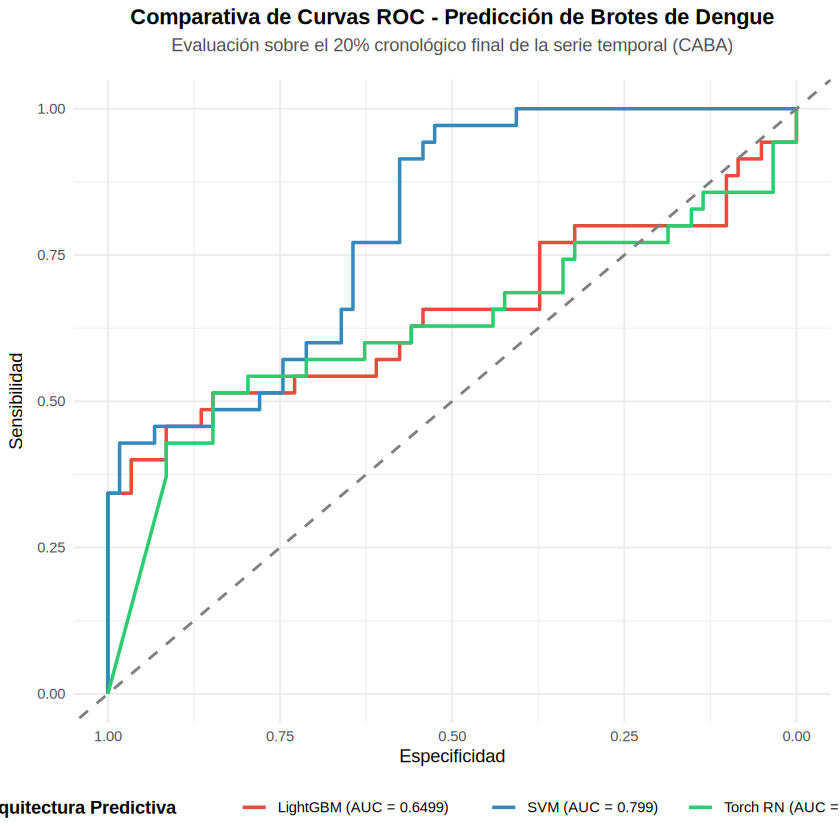

In [75]:
# 6.1 Predicciones sobre el Test Set
cat("Generando predicciones sobre el Test Set (Epidemia 2024)...\n")

# Extraemos los datos para SVM y LightGBM
x_test_matrix <- as.matrix(test_data[, ..features_model])
x_test_matrix[is.na(x_test_matrix)] <- 0
y_test_real <- as.numeric(as.character(test_data$is_brote))

# 1. Predicciones LightGBM
pred_lgb <- predict(modelo_lgb, x_test_matrix)

# 2. Predicciones SVM Lineal
pred_svm_raw <- predict(modelo_svm, x_test_matrix, decision.values = TRUE)
pred_svm <- as.numeric(attr(pred_svm_raw, "decision.values"))

# 3. Predicciones Torch
x_test_nn_vector <- as.numeric(unlist(test_data[, ..features_model]))
x_test_nn_clean <- matrix(x_test_nn_vector, nrow = nrow(test_data), byrow = FALSE)
x_test_nn_clean[is.na(x_test_nn_clean)] <- 0

x_test_t <- torch_tensor(x_test_nn_clean, dtype = torch_float32())
pred_torch_raw <- predict(modelo_torch, x_test_t) # <--- CAMBIO CLAVE
pred_torch <- as.numeric(pred_torch_raw)

# 6.2 Cálculo del AUC
roc_lgb <- roc(y_test_real, pred_lgb, quiet = TRUE, direction = "auto")
roc_svm <- roc(y_test_real, pred_svm, quiet = TRUE, direction = "auto")
roc_torch <- roc(y_test_real, pred_torch, quiet = TRUE, direction = "auto")

auc_lgb <- round(auc(roc_lgb), 4)
auc_svm <- round(auc(roc_svm), 4)
auc_torch <- round(auc(roc_torch), 4)

cat("\n--- Resultados de Discriminación (ROC AUC) ---\n")
cat("LightGBM AUC :", auc_lgb, "\n")
cat("SVM AUC      :", auc_svm, "\n")
cat("Torch RN AUC :", auc_torch, "\n\n")

# 6.3 Gráfico Comparativo
roc_list <- list("LightGBM" = roc_lgb, "SVM" = roc_svm, "Torch (RN)" = roc_torch)

roc_plot <- ggroc(roc_list, size = 1) +
  theme_minimal() +
  labs(
    title = "Comparativa de Curvas ROC - Predicción de Brotes de Dengue",
    subtitle = "Evaluación sobre el 20% cronológico final de la serie temporal (CABA)",
    x = "Especificidad",
    y = "Sensibilidad",
    color = "Arquitectura Predictiva"
  ) +
  geom_abline(slope = 1, intercept = 1, linetype = "dashed", color = "gray50", linewidth = 0.8) +
  scale_color_manual(
    labels = c(
      paste0("LightGBM (AUC = ", auc_lgb, ")"),
      paste0("SVM (AUC = ", auc_svm, ")"),
      paste0("Torch RN (AUC = ", auc_torch, ")")
    ),
    values = c("#E74C3C", "#348ABD", "#2ECC71")
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13),
    plot.subtitle = element_text(color = "gray30", hjust = 0.5, margin = margin(b=15)),
    legend.position = "bottom",
    legend.title = element_text(face = "bold")
  )

print(roc_plot)

## 7. Métricas de Rendimiento

En forma complementaria, se calculan las matrices de confusión y las métricas de rendimiento sobre el conjunto de evaluación (*Test Set*):

* **Sensibilidad (Recall):** Capacidad del modelo para detectar correctamente las semanas de brote epidémico real.
* **Especificidad:** Capacidad del modelo para identificar correctamente las semanas sin brote, evitando falsas alarmas.
* **Exactitud (Accuracy):** Porcentaje global de aciertos del modelo.


In [76]:
# 7.1 Cálculo de Métricas utilizando el Umbral Óptimo (Índice de Youden)

evaluar_modelo_metricas <- function(y_real, p_prob) {
  y_real_num <- as.numeric(as.character(y_real))

  # 1. Calculo la curva ROC
  roc_obj <- roc(y_real_num, p_prob, quiet = TRUE, direction = "auto")
  coords_opt <- coords(roc_obj, "best", best.method = "youden", ret = c("threshold", "specificity", "sensitivity"))

  umbral_optimo <- coords_opt$threshold[1]

  # 2. Conversión a binario
  if(roc_obj$direction == ">") {
    y_pred <- ifelse(p_prob <= umbral_optimo, 1, 0)
  } else {
    y_pred <- ifelse(p_prob >= umbral_optimo, 1, 0)
  }

  # 3. Matriz de confusión
  mat <- confusionMatrix(factor(y_pred, levels = c(0, 1)),
                         factor(y_real_num, levels = c(0, 1)),
                         positive = "1")

  acc <- mat$overall["Accuracy"]
  sens <- mat$byClass["Sensitivity"]
  spec <- mat$byClass["Specificity"]
  prec <- mat$byClass["Pos Pred Value"]
  f1 <- mat$byClass["F1"]

  return(c(Umbral_Optimo = round(umbral_optimo, 4),
           Accuracy = as.numeric(acc),
           Sensibilidad = as.numeric(sens),
           Especificidad = as.numeric(spec),
           Precision = as.numeric(prec),
           F1_Score = as.numeric(f1)))
}

# Evaluación de los modelos
res_lgb <- evaluar_modelo_metricas(test_data$is_brote, pred_lgb)
res_svm <- evaluar_modelo_metricas(test_data$is_brote, pred_svm)
res_torch <- evaluar_modelo_metricas(test_data$is_brote, pred_torch)


# Generación de la tabla
tabla_metricas <- data.frame(
  Modelo = c("LightGBM", "SVM Lineal", "Torch RN"),
  AUC = c(auc_lgb, auc_svm, auc_torch),
  Accuracy = c(res_lgb["Accuracy"], res_svm["Accuracy"], res_torch["Accuracy"]),
  Sensibilidad = c(res_lgb["Sensibilidad"], res_svm["Sensibilidad"], res_torch["Sensibilidad"]),
  Especificidad = c(res_lgb["Especificidad"], res_svm["Especificidad"], res_torch["Especificidad"]),
  F1_Score = c(res_lgb["F1_Score"], res_svm["F1_Score"], res_torch["F1_Score"])
)

cat("\n--- TABLA RESUMEN DEFINITIVA ---\n")
print(tabla_metricas)


--- TABLA RESUMEN DEFINITIVA ---
      Modelo    AUC  Accuracy Sensibilidad Especificidad  F1_Score
1   LightGBM 0.6499 0.7446809    0.4571429     0.9152542 0.5714286
2 SVM Lineal 0.7990 0.6914894    0.9714286     0.5254237 0.7010309
3   Torch RN 0.6274 0.7234043    0.5142857     0.8474576 0.5806452


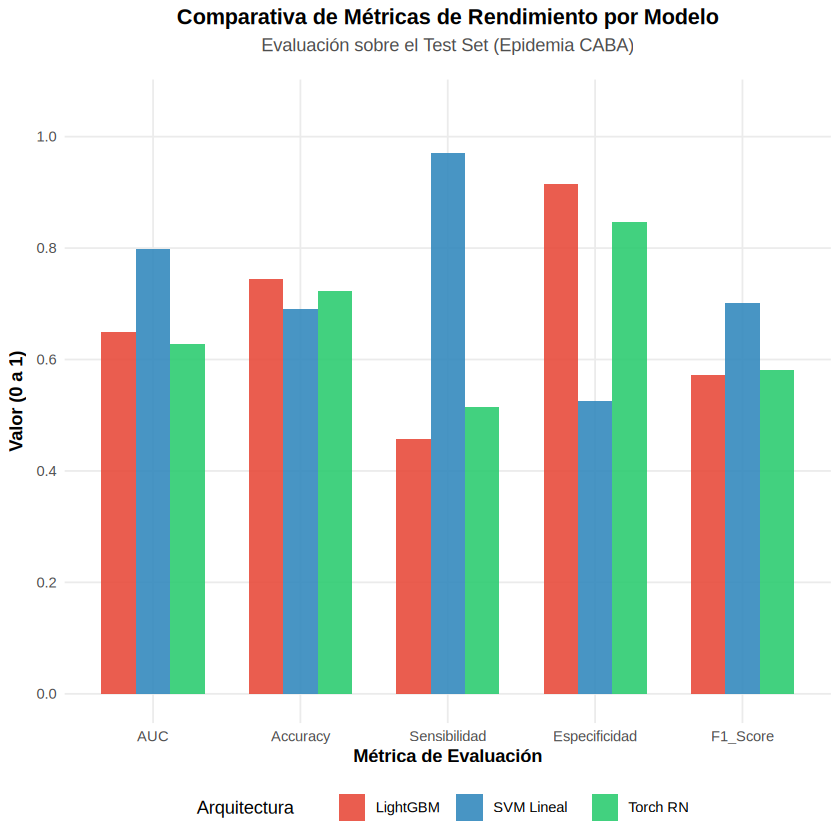

In [77]:
# 7.2 Gráfico de Barras Comparativo

library(reshape2)

# Transformamos la tabla a formato largo para ggplot2
tabla_melted <- melt(tabla_metricas, id.vars = "Modelo", variable.name = "Metrica", value.name = "Valor")

grafico_metricas <- ggplot(tabla_melted, aes(x = Metrica, y = Valor, fill = Modelo)) +
  geom_bar(stat = "identity", position = "dodge", width = 0.7, alpha = 0.9) +
  scale_y_continuous(limits = c(0, 1.05), breaks = seq(0, 1, 0.2)) +
  scale_fill_manual(values = c("#E74C3C", "#348ABD", "#2ECC71")) +
  theme_minimal() +
  labs(
    title = "Comparativa de Métricas de Rendimiento por Modelo",
    subtitle = "Evaluación sobre el Test Set (Epidemia CABA)",
    x = "Métrica de Evaluación",
    y = "Valor (0 a 1)",
    fill = "Arquitectura"
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13),
    plot.subtitle = element_text(color = "gray30", hjust = 0.5, margin = margin(b=15)),
    legend.position = "bottom",
    axis.title = element_text(face = "bold"),
    panel.grid.minor = element_blank()
  )

print(grafico_metricas)